# Module 3 · Uplift Modeling for Targeting with CausalML
**⏱ 30 minutes** · 1:45 – 2:15

**Learning objectives**
1. Frame targeting as an **uplift** (incremental response) problem, not a response problem.
2. Fit CausalML **meta-learners** (S, T, X, R) and an **uplift random forest**.
3. Evaluate uplift models with **gain / Qini curves and AUUC** — even though individual uplift is never observed.
4. Convert scores into a **profit-maximizing targeting depth**.

**Scenario B:** Marketing ran a **randomized** 50/50 test of a premium-card cross-sell offer on 20,000 customers. Next quarter we can only contact a fraction of the base. *Whom should we contact?*

> With **randomized** treatment there's no confounding, so the challenge shifts from *identification* to *estimating heterogeneity* and *evaluating targeting*.

In [1]:
import sys, pathlib, warnings, logging
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore"); logging.getLogger("causalml").setLevel(logging.ERROR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier, LGBMRegressor
from causal_utils import make_campaign_data

pd.set_option("display.precision", 4)
df = make_campaign_data(n=20_000, seed=7)
FEATS = ["age", "tenure", "num_products", "digital_engagement", "avg_balance_k",
         "recent_complaint", "has_mortgage"]
train, test = train_test_split(df, test_size=0.3, random_state=0, stratify=df.treatment)

def clf(): return LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=15, min_child_samples=50, verbose=-1)
def reg(): return LGBMRegressor(n_estimators=150, learning_rate=0.05, num_leaves=15, min_child_samples=50, verbose=-1)

rates = df.groupby("treatment")["conversion"].mean()
print(f"Conversion  control={rates[0]:.2%}  treated={rates[1]:.2%}  →  average uplift (ATE) = {rates[1]-rates[0]:+.2%}")

Conversion  control=22.67%  treated=27.77%  →  average uplift (ATE) = +5.11%


## 3.1 The four customer types

|  | Converts if **not** contacted | Doesn't convert if not contacted |
|---|---|---|
| **Converts if contacted** | 😐 *Sure things* — uplift ≈ 0 (wasted cost) | 🎯 **Persuadables** — positive uplift |
| **Doesn't convert if contacted** | 🐕 **Sleeping dogs** — *negative* uplift | 🪨 *Lost causes* — uplift ≈ 0 |

A **response model** ($P(\text{convert} \mid X, \text{treated})$) ranks *sure things* at the top. An **uplift model** ($P(Y=1 \mid X, T=1) - P(Y=1 \mid X, T=0)$) ranks *persuadables* at the top and *sleeping dogs* at the bottom.

In [2]:
# Peek at the (simulated) truth: who are the sleeping dogs?
seg = df.assign(complaint=df.recent_complaint.map({0: "no recent complaint", 1: "recent complaint"}),
                engagement=pd.cut(df.digital_engagement, [0, .33, .66, 1], labels=["low", "mid", "high"]))
seg.pivot_table(index="complaint", columns="engagement", values="true_uplift", aggfunc="mean", observed=False).style.format("{:+.1%}").background_gradient(cmap="RdYlGn", vmin=-.3, vmax=.3)

engagement,low,mid,high
complaint,,,
no recent complaint,-0.0%,+7.8%,+16.7%
recent complaint,-18.7%,-16.5%,-14.3%


## 3.2 Meta-learners in CausalML

| Learner | Recipe | Notes |
|---|---|---|
| **S-learner** | One model $\mu(X, T)$; uplift $= \mu(X,1) - \mu(X,0)$ | Simple; can shrink effects to 0 if $T$ is "unimportant" to the model |
| **T-learner** | Separate $\mu_1(X)$, $\mu_0(X)$; uplift $= \mu_1 - \mu_0$ | Noisy when groups are small |
| **X-learner** | T-learner + impute individual effects + model them, weighted by propensity | Good with imbalanced groups |
| **R-learner** | Minimize Robinson residual loss (the DML idea) | Orthogonal; needs good nuisance models |

API: `learner.fit(X, treatment, y, p=propensity)` → `learner.predict(X)`. In an RCT the propensity is known: **p = 0.5**.

In [3]:
from causalml.inference.meta import BaseSClassifier, BaseTClassifier, BaseXClassifier, BaseRClassifier

Xtr, ttr, ytr = train[FEATS].values, train.treatment.values, train.conversion.values
Xte = test[FEATS].values
p_tr, p_te = np.full(len(train), 0.5), np.full(len(test), 0.5)

learners = {
    "S-learner": BaseSClassifier(learner=clf()),
    "T-learner": BaseTClassifier(learner=clf()),
    "X-learner": BaseXClassifier(outcome_learner=clf(), effect_learner=reg()),
    "R-learner": BaseRClassifier(outcome_learner=clf(), effect_learner=reg(), random_state=0),
}
preds = test[["conversion", "treatment", "true_uplift"]].copy()
for name, lrn in learners.items():
    lrn.fit(X=Xtr, treatment=ttr, y=ytr, p=p_tr)
    preds[name] = lrn.predict(X=Xte, p=p_te).ravel()

# ATE with confidence interval straight from a meta-learner
ate, lb, ub = learners["X-learner"].estimate_ate(X=Xtr, treatment=ttr, y=ytr, p=p_tr)
print(f"X-learner ATE = {ate[0]:+.3%}  [95% CI {lb[0]:+.3%}, {ub[0]:+.3%}]")

X-learner ATE = +5.907%  [95% CI +4.603%, +7.212%]


## 3.3 Uplift trees & forests
Instead of fitting outcome models, **uplift trees** choose splits that maximize the *difference in treatment effect* between child nodes (divergence criteria: KL, Euclidean, χ², DDP...). CausalML expects treatment labels as strings with a named control group.

In [4]:
from causalml.inference.tree import UpliftRandomForestClassifier, UpliftTreeClassifier
t_str = np.where(ttr == 1, "offer", "control")

uplift_rf = UpliftRandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=200,
                                         min_samples_treatment=50, n_reg=100,
                                         evaluationFunction="KL", control_name="control", random_state=0)
uplift_rf.fit(Xtr, treatment=t_str, y=ytr)
preds["Uplift RF"] = uplift_rf.predict(Xte).ravel()

# A single shallow uplift tree is human-readable
from causalml.inference.tree import uplift_tree_string
tree = UpliftTreeClassifier(max_depth=3, min_samples_leaf=400, min_samples_treatment=100,
                            evaluationFunction="KL", control_name="control")
tree.fit(Xtr, treatment=t_str, y=ytr)
# Leaf values = [P(convert | control), P(convert | offer)]
uplift_tree_string(tree.fitted_uplift_tree, FEATS)

Failed to import duecredit due to No module named 'duecredit'


recent_complaint >= 0.5?
yes -> num_products >= 2.5?
		yes -> [np.float64(0.2926829268292683), np.float64(0.0695364238410596)]
		no  -> [np.float64(0.1222707423580786), np.float64(0.05063291139240506)]
no  -> tenure >= 4.950000047683716?
		yes -> digital_engagement >= 0.4934999942779541?
				yes -> [np.float64(0.2282541640962369), np.float64(0.29952267303102625)]
				no  -> [np.float64(0.2469879518072289), np.float64(0.19925971622455274)]
		no  -> digital_engagement >= 0.3334999978542328?
				yes -> [np.float64(0.21367521367521367), np.float64(0.388912399492171)]
				no  -> [np.float64(0.21957040572792363), np.float64(0.25605095541401274)]


### The "obvious" baseline: a response model
Many campaigns are targeted with a classic propensity-to-buy model trained on *treated* customers. Let's add it so we can see why that's a mistake.

In [5]:
resp = clf().fit(train.loc[train.treatment == 1, FEATS], train.loc[train.treatment == 1, "conversion"])
preds["Response model"] = resp.predict_proba(Xte)[:, 1]
preds["Random"] = np.random.default_rng(0).random(len(preds))
preds.head()

,conversion,treatment,true_uplift,S-learner,T-learner,X-learner,R-learner,Uplift RF,Response model,Random
12512,0,0,0.0391,0.0342,-0.0123,0.0278,0.0307,0.0672,0.2055,0.6370
6591,0,1,0.0712,0.0334,0.0293,0.0644,0.0966,0.0489,0.3080,0.2698
7370,0,1,0.0292,0.0645,0.0619,0.0481,0.0955,0.0791,0.2778,0.0410
8950,0,0,0.0477,0.0557,0.0914,0.0859,0.1040,0.1061,0.2783,0.0165
16660,0,0,0.2084,0.1468,0.1388,0.1383,0.1301,0.2157,0.3347,0.8133


## 3.4 Evaluating uplift models without individual ground truth
We never observe an individual's uplift. But because treatment was **randomized**, within *any* group of customers (e.g., the top 20% by score) the treated-vs-control difference is an unbiased estimate of that group's uplift.

- **Cumulative gain curve:** target the top-$k$ customers by score; y-axis = estimated incremental conversions.
- **Qini curve:** a closely related variant (scaled by group sizes).
- **AUUC / Qini coefficient:** area under those curves — the "AUC" of uplift modeling. Random targeting = diagonal.

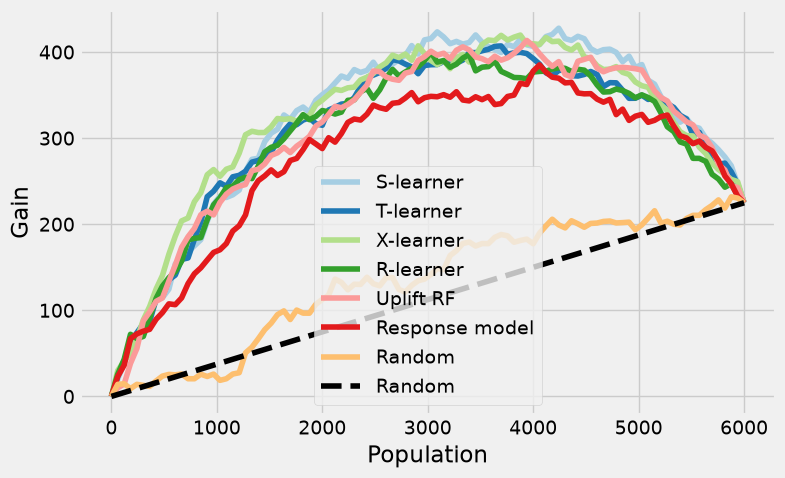

In [6]:
from causalml.metrics import plot_gain, plot_qini, auuc_score, qini_score

eval_df = preds.drop(columns=["true_uplift"])          # evaluate as you would in production
plot_gain(eval_df, outcome_col="conversion", treatment_col="treatment", figsize=(8, 5))
plt.show()
plt.style.use("default")   # CausalML switches matplotlib's global style; reset it

In [7]:
summary = pd.DataFrame({
    "AUUC (normalized)": auuc_score(eval_df, outcome_col="conversion", treatment_col="treatment", normalize=True),
    "Qini coefficient": qini_score(eval_df, outcome_col="conversion", treatment_col="treatment"),
    "corr with TRUE uplift": {c: np.corrcoef(preds[c], preds.true_uplift)[0, 1] for c in eval_df.columns
                              if c not in ("conversion", "treatment")},
}).sort_values("Qini coefficient", ascending=False)
summary

,AUUC (normalized),Qini coefficient,corr with TRUE uplift
S-learner,1.4278,0.9117,0.9080
X-learner,1.4257,0.9100,0.8766
Uplift RF,1.3697,0.8661,0.8905
T-learner,1.3673,0.8607,0.8066
R-learner,1.3360,0.8187,0.7972
Response model,1.2336,0.7157,0.6742
Random,0.5959,0.0925,-0.0172


**Notice the response model.** It's a good *conversion* predictor but a clearly weaker *uplift* ranker: it prioritizes high-balance, multi-product customers who would buy anyway (*sure things*) and doesn't penalize *sleeping dogs*.

### Uplift by decile — the chart business stakeholders understand

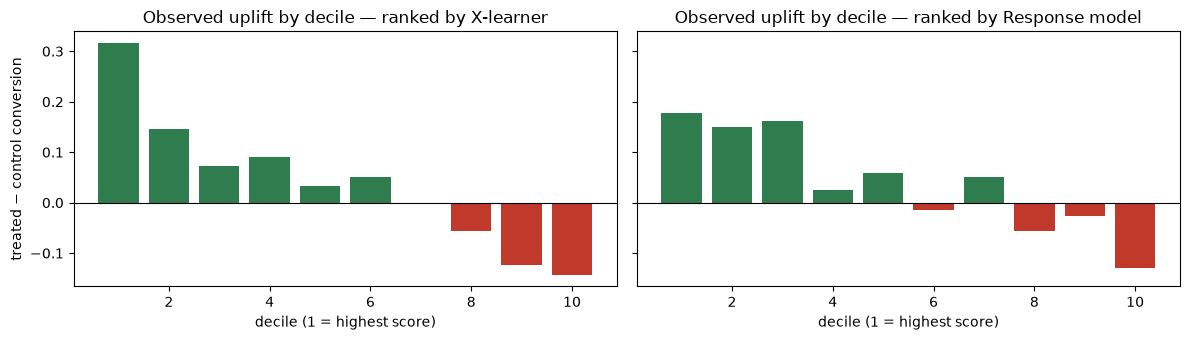

In [8]:
def uplift_by_decile(df_, score_col, n=10):
    d = df_.copy()
    d["decile"] = pd.qcut(d[score_col].rank(method="first", ascending=False), n, labels=range(1, n + 1))
    g = d.groupby(["decile", "treatment"], observed=False)["conversion"].mean().unstack()
    return g[1] - g[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, col in zip(ax, ["X-learner", "Response model"]):
    u = uplift_by_decile(preds, col)
    a.bar(u.index.astype(int), u.values, color=np.where(u.values >= 0, "#2f7d4f", "#c0392b"))
    a.axhline(0, color="k", lw=.8); a.set_title(f"Observed uplift by decile — ranked by {col}")
    a.set_xlabel("decile (1 = highest score)")
ax[0].set_ylabel("treated − control conversion"); plt.tight_layout(); plt.show()

A good uplift model gives a **monotone staircase** with *negative* uplift in the bottom deciles — those are customers we should actively **not** contact.

## 3.5 From scores to a business decision: how deep should we target?
Assume each contact costs **\$8** (incentive + ops) and each incremental premium-card conversion is worth **\$120** in first-year value (illustrative). Using the randomized holdout, we estimate incremental profit for each targeting depth.

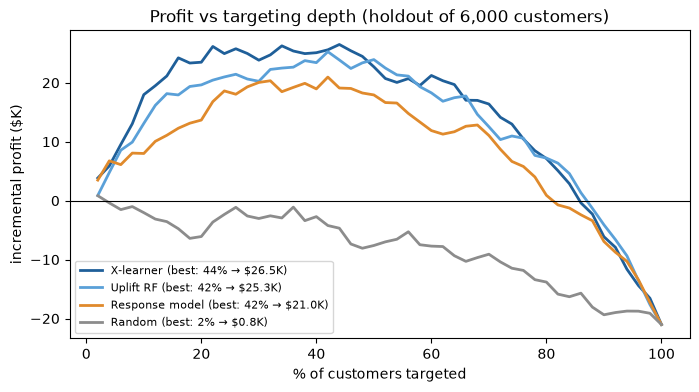

In [9]:
COST, VALUE = 8.0, 120.0

def profit_curve(df_, score_col, steps=50):
    d = df_.sort_values(score_col, ascending=False).reset_index(drop=True)
    N, out = len(d), []
    for frac in np.linspace(0.02, 1.0, steps):
        top = d.iloc[: int(frac * N)]
        uplift = top.loc[top.treatment == 1, "conversion"].mean() - top.loc[top.treatment == 0, "conversion"].mean()
        n_target = frac * N
        out.append((frac, n_target * (uplift * VALUE - COST)))
    return pd.DataFrame(out, columns=["frac", "profit"]).set_index("frac")["profit"]

fig, ax = plt.subplots(figsize=(8, 4))
for col, color in [("X-learner", "#1f5f99"), ("Uplift RF", "#5aa0d8"),
                   ("Response model", "#e08a2c"), ("Random", "#8c8c8c")]:
    pc = profit_curve(preds, col)
    ax.plot(pc.index * 100, pc.values / 1e3, color=color, lw=2,
            label=f"{col} (best: {pc.idxmax():.0%} → ${pc.max()/1e3:,.1f}K)")
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("% of customers targeted"); ax.set_ylabel("incremental profit ($K)")
ax.set_title("Profit vs targeting depth (holdout of 6,000 customers)"); ax.legend(fontsize=8); plt.show()

**Reading the chart:** with an uplift model, profit peaks when targeting roughly the top 40–45%. Contacting *everyone* **loses money** — wasted cost on sure things and lost conversions from sleeping dogs. The response model's peak is noticeably lower, and random targeting never pays.

---
## ✋ Exercise 3.1 (6 min) — sleeping dogs & feature drivers
1. Using the **X-learner** predictions in `preds`, what share of the test set has predicted uplift < 0? What's their recent-complaint rate vs the rest?
2. Use `learners["X-learner"].get_importance(X=Xte, tau=preds["X-learner"].values, features=FEATS, method="auto")` to see which features drive the predicted uplift. Do they match the true data-generating process (`digital_engagement`, `recent_complaint`, `tenure`, `age`)?

In [10]:
# YOUR CODE HERE

**✅ Solution (instructor copy)**

Predicted sleeping dogs: 27.8% of customers
Recent-complaint rate: sleeping dogs 30.2% vs others 0.1%


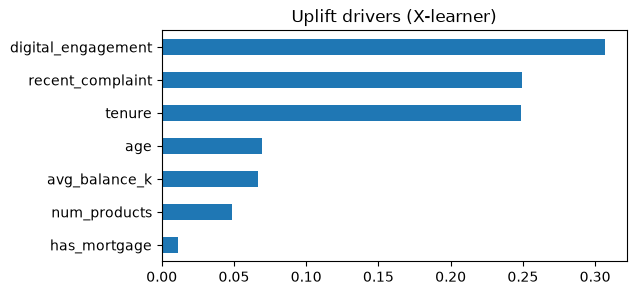

In [11]:
neg = preds["X-learner"] < 0
print(f"Predicted sleeping dogs: {neg.mean():.1%} of customers")
print(f"Recent-complaint rate: sleeping dogs {test.loc[neg.values,'recent_complaint'].mean():.1%} "
      f"vs others {test.loc[~neg.values,'recent_complaint'].mean():.1%}")
imp = learners["X-learner"].get_importance(X=Xte, tau=preds["X-learner"].values,
                                           features=FEATS, method="auto")
pd.Series(list(imp.values())[0]).sort_values().plot.barh(title="Uplift drivers (X-learner)", figsize=(6, 3))
plt.show()
# The top drivers match the simulation: engagement, complaints, tenure, age.
# num_products / avg_balance drive BASELINE conversion, not uplift -- exactly why
# the response model ranks the wrong people.

## ✋ Exercise 3.2 (optional / take-home) — campaign economics
Re-run the profit curve with **COST = \$20** (e.g., a richer incentive). How does the optimal targeting depth change for the X-learner? Is it still worth running the campaign at all?

In [12]:
# YOUR CODE HERE

**✅ Solution (instructor copy)**

In [13]:
COST = 20.0
pc = profit_curve(preds, "X-learner")
print(f"Optimal depth at $20/contact: {pc.idxmax():.0%} of base → ${pc.max()/1e3:,.1f}K; "
      f"targeting everyone → ${pc.iloc[-1]/1e3:,.1f}K")
COST = 8.0  # reset

Optimal depth at $20/contact: 16% of base → $12.7K; targeting everyone → $-93.0K


## 🔑 Key takeaways — Module 3
1. **Target the persuadables, not the likely buyers.** Response models ≠ uplift models.
2. **Randomized data is gold** — it makes uplift evaluation (gain/Qini/AUUC) possible on a holdout. Invest in always-on control groups.
3. Meta-learners turn any classifier into an uplift model; uplift forests optimize for heterogeneity directly. Compare them by **Qini/AUUC**, then translate to **profit vs depth**.
4. Negative uplift (*sleeping dogs*) is real — e.g., recently-complaining customers. Suppression lists are a causal decision.

☕ **5-minute break** → `04_Causal_Discovery_causal-learn.ipynb`